04 — Système hybride avec rejet de l'inconnu (Partie 4, cœur du projet)

Exigence n°3 du cahier des charges : **ne pas se tromper avec aplomb**. Face à une maladie jamais vue ou à une image qui n'est pas une feuille de tomate, le système doit répondre **« inconnu »**.

**Protocole *leave-one-class-out*.** Une maladie M (`part4.unknown_class`, par défaut *Tomato_mosaic_virus*) est **retirée entièrement** de l'entraînement du classifieur (9 classes connues). À l'évaluation, ses images doivent être déclarées « inconnu ».

**Pourquoi la mosaïque ?** — c'est une virose : nouvelles souches et virus émergents de la même famille (ex. *Tomato brown rugose fruit virus*, tobamovirus en expansion mondiale) sont exactement le type de maladie « jamais vue » qu'un outil déployé rencontrera ; c'est une petite classe (~2 % des images) ; et ses symptômes (marbrure vert clair/vert foncé, déformation) ne ressemblent pas aux taches nécrotiques des autres maladies, ce qui teste si le classifieur « invente » quand même un diagnostic.

Trois familles de rejet sont comparées **au même taux de rejet à tort (5 %) fixé sur la validation des classes connues** :
1. **MSP** (*maximum softmax probability*) du classifieur ;
2. **auto-encodeur** (erreur de reconstruction) ;
3. **hybride** : règle « OU » et score combiné normalisé (z-scores).


In [1]:
# === Configuration (Colab, Kaggle ou local) ===
ALLOW_CPU = False   # True seulement pour les notebooks sans entraînement (00 et 06)
REPO_URL = "https://github.com/fayelise/diagnoculture.git"   # utilisé sur Kaggle uniquement



import os, sys, subprocess
from pathlib import Path

# 1. Environnement. Colab est testé AVANT Kaggle : sur Colab, kagglehub peut créer /kaggle/input.
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ
IN_KAGGLE = not IN_COLAB and "KAGGLE_KERNEL_RUN_TYPE" in os.environ

if IN_COLAB:
    # Projet sur Google Drive : résultats et checkpoints survivent aux déconnexions
    from google.colab import drive, userdata
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/diagnoculture")
    os.environ["DIAGNO_CACHE"] = "/content/cache"   # cache d'images sur le disque local de Colab (rapide)
    for name in ("KAGGLE_API_TOKEN", "KAGGLE_USERNAME", "KAGGLE_KEY"):   # jeton Kaggle (Secrets Colab)
        try:
            os.environ[name] = userdata.get(name)
        except Exception:
            pass
elif IN_KAGGLE:
    # Code cloné depuis GitHub ; résultats du notebook précédent (ajouté en Input) recopiés
    # dans /kaggle/working : l'Output de ce notebook contiendra donc toute la chaîne.
    import shutil
    ROOT = Path("/kaggle/working/diagnoculture")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(ROOT)], check=True)
    for inp in Path("/kaggle/input").iterdir():
        for prev in (inp / "results", inp / "diagnoculture" / "results"):
            if (prev / "00_split").is_dir():
                shutil.copytree(prev, ROOT / "results", dirs_exist_ok=True)
else:
    # Local : notebook lancé depuis notebooks/ ou depuis la racine du dépôt
    ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent

assert (ROOT / "src" / "utils.py").exists(), f"Projet introuvable dans {ROOT} (voir README, section Installation)"
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

# 2. Paquets absents des images Colab / Kaggle (en local : pip install -r requirements.txt)
if IN_COLAB or IN_KAGGLE:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torchinfo==1.8.0", "ImageHash==4.3.2",
                    "grad-cam==1.5.7", "onnx==1.23.2", "onnxruntime==1.29.0",
                    "umap-learn==0.5.12", "kagglehub==1.0.2"], check=True)

# 3. Configuration du projet
from src.utils import load_config, resolve_paths, set_seed, ensure_data, get_device, machine_info, TestGuard
cfg = load_config()
set_seed(cfg["seed"])
paths = resolve_paths(cfg)
DATA_ROOT = ensure_data(cfg)          # télécharge PlantVillage au 1er lancement de la session (hors Kaggle)
DEVICE = get_device()
guard = TestGuard(paths["results"])   # le test ne sert qu'une fois par modèle final
FORCE_TEST_RERUN = False              # True uniquement pour ré-exécuter à l'identique après une coupure
print("Projet :", ROOT, "| données :", DATA_ROOT, "| device :", DEVICE)
print(machine_info())

# 4. Garde-fou GPU : sur CPU, chaque epoch est 40 à 80 fois plus lente et le budget train.max_minutes
#    coupe les entraînements après 1 à 4 epochs (cause des résultats invalides de la 1re exécution).
#    DIAGNO_ALLOW_CPU=1 sert uniquement au test rapide du pipeline (README).
if DEVICE.type != "cuda" and not (ALLOW_CPU or os.environ.get("DIAGNO_ALLOW_CPU") == "1"):
    raise RuntimeError("Pas de GPU : Exécution → Modifier le type d'exécution → T4 GPU "
                       "(Kaggle : Session options → Accelerator → GPU T4).")

Mounted at /content/drive
Téléchargement de abdallahalidev/plantvillage-dataset via kagglehub (~2 Go, quelques minutes)...
Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
Données téléchargées dans : /kaggle/input/plantvillage-dataset
Projet : /content/drive/MyDrive/diagnoculture | données : /kaggle/input/plantvillage-dataset/plantvillage dataset/color | device : cuda
{'env': 'colab', 'python': '3.13.16', 'torch': '2.11.0+cu130', 'cpu': 'x86_64', 'cpu_count': 2, 'gpu': 'Tesla T4'}


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import roc_auc_score

from src.datasets import (CLASSES, HEALTHY, IMAGENET_MEAN, IMAGENET_STD, FolderImages, TensorImageDataset,
                          build_transform, get_split_tensors, load_split, make_loader)
from src.metrics import classification_metrics, plot_confusion
from src.models import ConvAutoencoder, TransferModel, apply_strategy
from src.ood import (coverage_accuracy, fit_rule, list_images, msp_unknown_score, open_set_metrics,
                     plot_coverage_accuracy, reject, unknown_score)
from src.train import fit_classifier, fit_reconstruction, load_best, predict_logits, reconstruction_scores, record_experiment
from src.utils import load_json, save_json

P4 = cfg["part4"]
OUT = paths["results"] / "04_hybrid"
OUT.mkdir(parents=True, exist_ok=True)
BS, NW = cfg["train"]["batch_size"], cfg["data"]["num_workers"]
S_CLS, S_AE = cfg["resolution"]["transfer"], cfg["resolution"]["ae"]
M = P4["unknown_class"]
M_IDX = CLASSES.index(M)
KNOWN = [c for c in CLASSES if c != M]
remap = {CLASSES.index(c): i for i, c in enumerate(KNOWN)}   # étiquettes 0..8 pour le classifieur à 9 classes
best_ae_info = load_json(paths["results"] / "03_autoencoders" / "best_ae.json")
print("Classe inconnue M :", M, "| classes connues :", KNOWN)

Classe inconnue M : Tomato_mosaic_virus | classes connues : ['Bacterial_spot', 'Early_blight', 'Late_blight', 'Leaf_Mold', 'Septoria_leaf_spot', 'Spider_mites', 'Target_Spot', 'Yellow_Leaf_Curl_Virus', 'healthy']


In [3]:
d_cls = get_split_tensors(paths, DATA_ROOT, S_CLS)   # 224x224 pour le classifieur
d_ae = get_split_tensors(paths, DATA_ROOT, S_AE)     # 64x64 pour les auto-encodeurs
tf_cls_train = build_transform(True, IMAGENET_MEAN, IMAGENET_STD)
tf_cls = build_transform(False, IMAGENET_MEAN, IMAGENET_STD)
tf_ae_train, tf_ae = build_transform(True, augment="flip"), build_transform(False)

def select(d, split, known):
    df, x = d[split]
    mask = (df["label"] != M_IDX).to_numpy() if known else (df["label"] == M_IDX).to_numpy()
    return df[mask].reset_index(drop=True), x[torch.tensor(mask)]

sets = {}   # nom -> (DataFrame, tenseur 224, tenseur 64)
for split in ("train", "val", "test"):
    df, x224 = select(d_cls, split, True)
    _, x64 = select(d_ae, split, True)
    sets[f"{split}_known"] = (df, x224, x64)
# M : aucune de ses images n'a servi à entraîner ni à régler quoi que ce soit -> toutes sont « jamais vues »
parts = [select(d_cls, s, False) + (select(d_ae, s, False)[1],) for s in ("train", "val", "test")]
sets["unknown_M"] = (pd.concat([p[0] for p in parts], ignore_index=True), torch.cat([p[1] for p in parts]),
                     torch.cat([p[2] for p in parts]))
print({k: len(v[0]) for k, v in sets.items()})

def loaders(name, bs=128):
    df, x224, x64 = sets[name]
    y = df["label"].map(remap).fillna(-1).astype(int)
    return (make_loader(TensorImageDataset(x224, y, tf_cls), bs, False, NW),
            make_loader(TensorImageDataset(x64, y, tf_ae), 256, False, NW))

{'train_known': 12451, 'val_known': 2666, 'test_known': 2670, 'unknown_M': 373}


#1. Classifieur à 9 classes (M exclue)
#
# Même backbone et même stratégie que le meilleur modèle de la partie 2 (config `part4.backbone`, `part4.strategy`), réentraîné sans M.

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 114MB/s] 


Reprise depuis l'epoch 6 (temps déjà écoulé : 5.1 min)


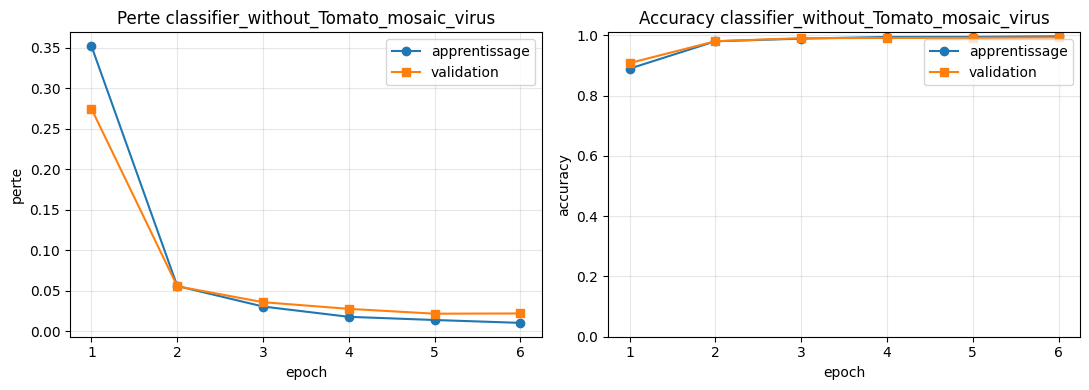

In [4]:
set_seed(cfg["seed"])
clf = TransferModel(P4["backbone"], len(KNOWN), pretrained=cfg["part2"]["pretrained"])
groups = apply_strategy(clf, P4["strategy"], cfg["part2"]["lr_head"], cfg["part2"]["backbone_lr_factor"])
df_tr, x_tr, _ = sets["train_known"]
train_loader = make_loader(TensorImageDataset(x_tr, df_tr["label"].map(remap), tf_cls_train), BS, True, NW, cfg["seed"])
val_cls_loader, val_ae_loader = loaders("val_known")
hp_clf = {"backbone": P4["backbone"], "strategy": P4["strategy"], "classes": KNOWN, "excluded": M,
          "epochs": P4["epochs"], "lr_head": cfg["part2"]["lr_head"], "img_size": S_CLS}
exp_clf = OUT / f"classifier_without_{M}"
fit_classifier(clf, train_loader, val_cls_loader, exp_clf, P4["epochs"], groups, cfg["part2"]["weight_decay"],
               cfg["train"]["amp"], cfg["train"]["max_minutes"], cfg["train"]["resume"], hparams=hp_clf)
clf = load_best(clf, exp_clf)

2. Auto-encodeurs

- **AE-sain** : le modèle final de la partie 3 (entraîné uniquement sur des feuilles saines).
- **AE-connues** (variante proposée) : même architecture, entraîné sur **toutes les classes connues** (9 classes, M exclue).

Point clé de la discussion : l'AE-sain considère **toute** maladie comme une anomalie, y compris les maladies **connues** que le classifieur sait diagnostiquer. Dans un système de rejet, il rejettera donc à tort beaucoup d'images connues malades (ou, si son seuil est réglé pour ne pas les rejeter, il ne distinguera plus M des autres maladies). L'AE-connues modélise au contraire « ce qu'est une image du domaine connu » : c'est le bon complément d'un classifieur pour la détection de **nouveauté**.

Reprise depuis l'epoch 25 (temps déjà écoulé : 1.7 min)


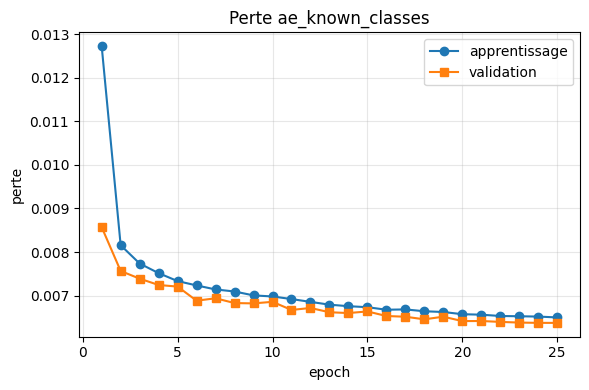

In [5]:
ae_h = load_best(ConvAutoencoder(best_ae_info["latent_dim"]), paths["results"] / best_ae_info["exp_dir"])

set_seed(cfg["seed"])
ae_k = ConvAutoencoder(best_ae_info["latent_dim"])
_, _, x64_tr = sets["train_known"]
_, _, x64_va = sets["val_known"]
hp_aek = {"latent_dim": best_ae_info["latent_dim"], "train_data": f"9 classes connues (sans {M})",
          "epochs": P4["ae_known_epochs"], "lr": cfg["part3"]["lr"], "img_size": S_AE}
exp_aek = OUT / "ae_known_classes"
fit_reconstruction(ae_k, make_loader(TensorImageDataset(x64_tr, np.zeros(len(x64_tr)), tf_ae_train), BS, True, NW, cfg["seed"]),
                   make_loader(TensorImageDataset(x64_va, np.zeros(len(x64_va)), tf_ae), 256, False, NW),
                   exp_aek, P4["ae_known_epochs"], cfg["part3"]["lr"], "ae", amp=cfg["train"]["amp"],
                   max_minutes=cfg["train"]["max_minutes"], resume=cfg["train"]["resume"], hparams=hp_aek)
ae_k = load_best(ae_k, exp_aek)
_ = record_experiment(paths["results"], "P4_ae_known_classes", "4", ae_k, exp_aek, S_AE, hparams=hp_aek)

3. Calcul des scores d'étrangeté

Pour chaque image : `msp` = 1 − MSP ; `ae_healthy` et `ae_known` = erreur de reconstruction. **Plus le score est élevé, plus l'image est suspecte.**

In [6]:
@torch.no_grad()
def compute_scores(cls_loader, ae_loader):
    logits, y = predict_logits(clf, cls_loader)
    return {"logits": logits, "y": y.numpy(), "pred": logits.argmax(1).numpy(), "msp": msp_unknown_score(logits),
            "ae_healthy": reconstruction_scores(ae_h, ae_loader)["mse"],
            "ae_known": reconstruction_scores(ae_k, ae_loader)["mse"]}

scores = {"val_known": compute_scores(val_cls_loader, val_ae_loader)}

## 4. Règles de décision, toutes fixées sur la VALIDATION (classes connues uniquement)

Chaque système vise **5 % de rejet à tort** des connues de validation (`part4.target_false_reject`) : même « prix » payé sur les connues, on compare ce que chacun obtient sur l'inconnu.

| Système             | Règle                                                                                                | Justification                                                                                                                                                    |
|:--------------------|:-----------------------------------------------------------------------------------------------------|:-----------------------------------------------------------------------------------------------------------------------------------------------------------------|
| MSP                 | rejet si $1-\max_c p(c\mid x) > \tau$                                                                | baseline : un classifieur hésitant est un indice d'inconnu                                                                                                       |
| AE                  | rejet si $\lVert x-\hat x\rVert^2 > \tau$                                                            | l'image s'écarte de ce que l'AE sait reconstruire                                                                                                                |
| Hybride **OU**      | rejet si $(1-\text{MSP} > \tau_1)$ **ou** $(\text{erreur} > \tau_2)$, chacun à 2,5 % de rejet à tort | les deux signaux sont complémentaires : il suffit que l'un des deux alerte. Budget partagé (correction de Bonferroni) pour garder ≈ 5 % au total                 |
| Hybride **z-score** | rejet si $\frac{1}{2}(z_{\text{MSP}} + z_{\text{AE}}) > \tau$, z calculés sur la validation          | échelles très différentes (MSP ∈ [0,1], MSE ~ 10⁻³) → on standardise avant de sommer ; un signal modérément élevé sur les deux critères est aussi pris en compte |

Les seuils de la règle « OU » sont fixés séparément puis combinés ; le taux réel de rejet à tort sur la validation est vérifié ci-dessous.

In [7]:
SYSTEMS = {"msp": ("msp", None), "ae_healthy": ("ae", "ae_healthy"), "ae_known": ("ae", "ae_known"),
           "or_healthy": ("or", "ae_healthy"), "z_healthy": ("z", "ae_healthy"),
           "or_known": ("or", "ae_known"), "z_known": ("z", "ae_known")}
v = scores["val_known"]
rules = {}
for name, (kind, ae_key) in SYSTEMS.items():
    ae_val = v[ae_key] if ae_key else np.zeros_like(v["msp"])
    rules[name] = fit_rule(kind, v["msp"], ae_val, P4["target_false_reject"], split_name="val")
    rules[name]["ae"] = ae_key
check = {n: float(reject(r, v["msp"], v[r["ae"]] if r["ae"] else 0 * v["msp"]).mean()) for n, r in rules.items()}
print("Taux de rejet à tort sur la validation (cible 5 %) :", {k: round(x, 3) for k, x in check.items()})
save_json(rules, OUT / "rules_fitted_on_val.json")

Taux de rejet à tort sur la validation (cible 5 %) : {'msp': 0.05, 'ae_healthy': 0.05, 'ae_known': 0.05, 'or_healthy': 0.05, 'z_healthy': 0.05, 'or_known': 0.049, 'z_known': 0.05}


# 5. Évaluation sur le test (connues) et sur M — **une seule fois**

Classifieur 9 classes, test (connues) : accuracy 0.9966, F1 macro 0.9959


,auroc_known_vs_unknown,reject_rate_unknown,false_reject_rate_known,accuracy_on_accepted_known,coverage_known
système,,,,,
msp,0.9631,0.7936,0.0536,0.9996,0.9464
ae_healthy,0.3284,0.0027,0.0569,0.9972,0.9431
ae_known,0.3924,0.0000,0.0644,0.9972,0.9356
or_healthy,0.8020,0.6649,0.0558,0.9996,0.9442
z_healthy,0.7669,0.4826,0.0577,0.9988,0.9423
or_known,0.8177,0.6622,0.0603,0.9996,0.9397
z_known,0.7835,0.4906,0.0596,0.9992,0.9404


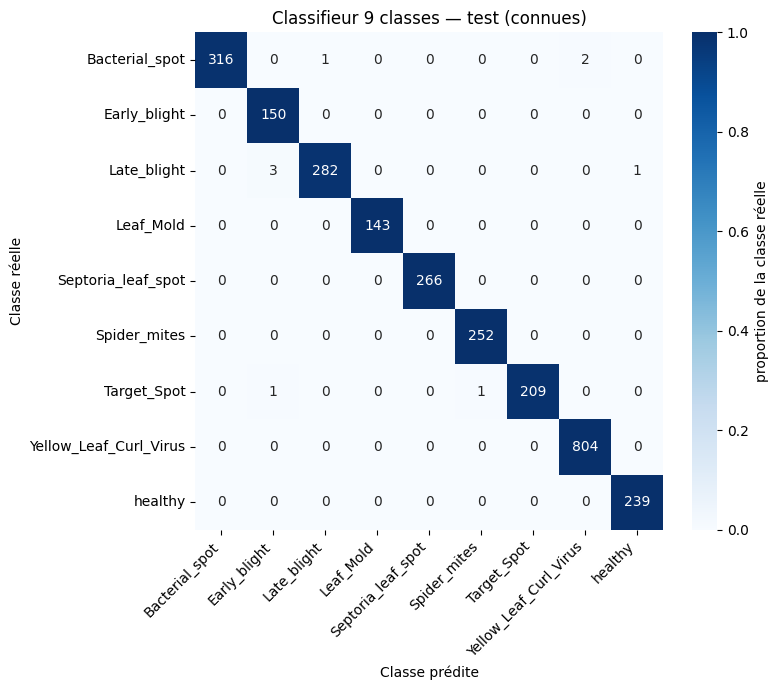

In [9]:
guard.register("P4_open_set_systems", force=FORCE_TEST_RERUN)
scores["test_known"] = compute_scores(*loaders("test_known"))
scores["unknown_M"] = compute_scores(*loaders("unknown_M"))
tk, um = scores["test_known"], scores["unknown_M"]

def sys_scores(name, s):
    r = rules[name]
    return unknown_score(r, s["msp"], s[r["ae"]] if r["ae"] else 0 * s["msp"])

rows = []
for name, r in rules.items():
    sk, su = sys_scores(name, tk), sys_scores(name, um)
    rows.append({"système": name, **open_set_metrics(sk, su, sk > r["tau"], su > r["tau"], tk["pred"], tk["y"])})
results = pd.DataFrame(rows).set_index("système").round(4)
results.to_csv(OUT / "open_set_results_test.csv")

# Classifieur seul (monde fermé, 9 classes) : référence
cm = classification_metrics(tk["y"], tk["pred"], KNOWN)
save_json(cm, exp_clf / "test_metrics.json")
plot_confusion(cm["confusion_matrix"], KNOWN, exp_clf / "confusion_test.png", "Classifieur 9 classes — test (connues)")
record_experiment(paths["results"], f"P4_classifier_without_{M}", "4", clf, exp_clf, S_CLS, cm, hp_clf)
print(f"Classifieur 9 classes, test (connues) : accuracy {cm['accuracy']:.4f}, F1 macro {cm['f1_macro']:.4f}")
for name, row in results.iterrows():
    record_experiment(paths["results"], f"P4_system_{name}", "4", clf, exp_clf, S_CLS, hparams=rules[name],
                      extra_metric="AUROC connu/M | rejet M | rejet à tort | acc. acceptées",
                      extra_value=f"{row['auroc_known_vs_unknown']} | {row['reject_rate_unknown']} | "
                                  f"{row['false_reject_rate_known']} | {row['accuracy_on_accepted_known']}")
results

Que prédit le classifieur sur M quand il ne rejette pas ?
C'est la démonstration du problème « se tromper avec aplomb » : une maladie inconnue reçoit quand même un diagnostic, souvent avec une forte confiance.

In [10]:
pred_names = pd.Series(np.array(KNOWN)[um["pred"]]).value_counts()
print(f"Images de {M} : MSP médiane = {1 - np.median(um['msp']):.3f}  (connues du test : {1 - np.median(tk['msp']):.3f})")
print("Diagnostics attribués à M par le classifieur seul :\n", pred_names)

Images de Tomato_mosaic_virus : MSP médiane = 0.917  (connues du test : 1.000)
Diagnostics attribués à M par le classifieur seul :
 Septoria_leaf_spot        183
Spider_mites               96
Leaf_Mold                  68
Target_Spot                12
Yellow_Leaf_Curl_Virus     10
Early_blight                3
Late_blight                 1
Name: count, dtype: int64


# Distributions des scores et courbe couverture / précision

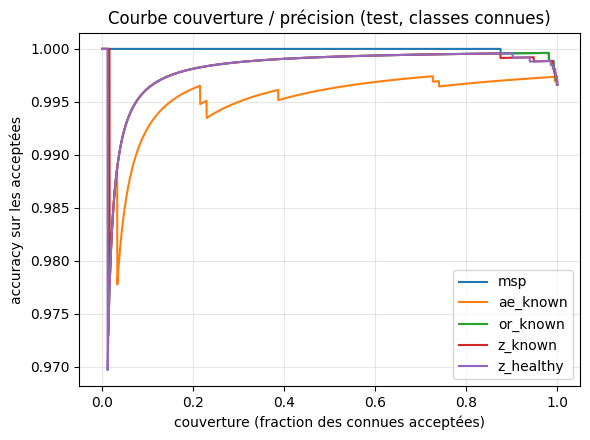

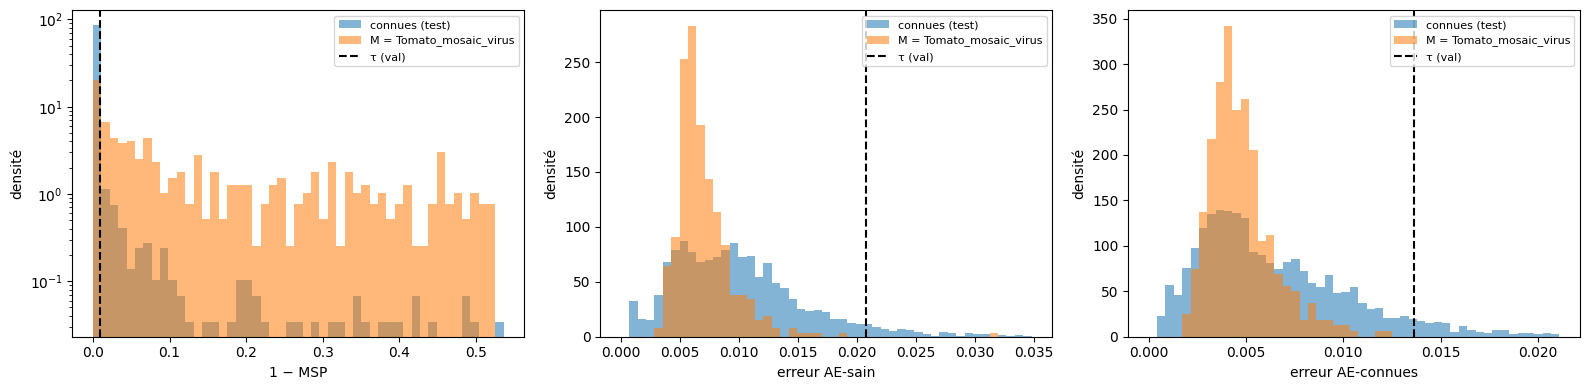

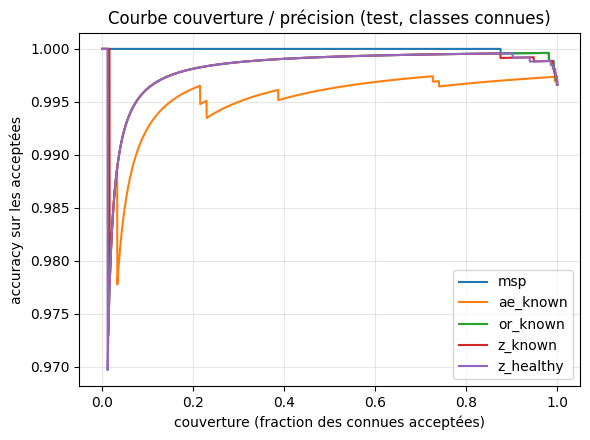

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, key, lab in [(axes[0], "msp", "1 − MSP"), (axes[1], "ae_healthy", "erreur AE-sain"), (axes[2], "ae_known", "erreur AE-connues")]:
    hi = np.percentile(np.r_[tk[key], um[key]], 99.5)
    bins = np.linspace(0, hi, 50)
    ax.hist(tk[key], bins, alpha=0.55, density=True, label="connues (test)")
    ax.hist(um[key], bins, alpha=0.55, density=True, label=f"M = {M}")
    ax.axvline(rules[key]["tau"], color="k", ls="--", label="τ (val)")   # système « seul » du même nom
    ax.set(xlabel=lab, ylabel="densité", yscale="log" if key == "msp" else "linear")
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "score_distributions.png", dpi=150)

correct = tk["pred"] == tk["y"]
plot_coverage_accuracy({n: coverage_accuracy(sys_scores(n, tk), correct) for n in ["msp", "ae_known", "or_known", "z_known", "z_healthy"]},
                       OUT / "coverage_accuracy.png")

# L'AE-sain rejette les maladies connues (taux de rejet par classe connue, test)

In [12]:
per_cls = pd.DataFrame({"classe": np.array(KNOWN)[tk["y"]],
                        "AE-sain": tk["ae_healthy"] > rules["ae_healthy"]["tau"],
                        "AE-connues": tk["ae_known"] > rules["ae_known"]["tau"],
                        "MSP": tk["msp"] > rules["msp"]["tau"]}).groupby("classe").mean().round(3)
per_cls.to_csv(OUT / "reject_rate_per_known_class.csv")
per_cls

,AE-sain,AE-connues,MSP
classe,,,
Bacterial_spot,0.000,0.000,0.072
Early_blight,0.187,0.247,0.187
Late_blight,0.231,0.203,0.126
Leaf_Mold,0.042,0.063,0.021
Septoria_leaf_spot,0.128,0.094,0.026
Spider_mites,0.000,0.004,0.103
Target_Spot,0.019,0.118,0.057
Yellow_Leaf_Curl_Virus,0.016,0.006,0.005
healthy,0.004,0.050,0.017


6. Robustesse hors-distribution (non-feuilles de tomate)

Deux sources : feuilles d'**autres espèces PlantVillage** (même fond de laboratoire : test difficile, l'image « ressemble » au domaine) et **photos personnelles** (`data/ood/custom/` : mains, sol, autres plantes, feuilles de tomate sur fond naturel — décalage de domaine réel).
Seuils inchangés (ceux de la validation).

In [13]:
ood_sets = {"autres espèces PlantVillage": [DATA_ROOT / r for r in load_split(paths["split_dir"], "ood_plantvillage")["relpath"]],
            "photos personnelles": list_images(paths["ood_custom"])}
ood_rows = []
for oname, files in ood_sets.items():
    if not files:
        print(f"(aucune image pour « {oname} »)")
        continue
    s = compute_scores(make_loader(FolderImages(files, S_CLS, tf_cls), 64, False, NW),
                       make_loader(FolderImages(files, S_AE, tf_ae), 256, False, NW))
    scores[oname] = s
    for name, r in rules.items():
        so, sk = sys_scores(name, s), sys_scores(name, tk)
        ood_rows.append({"jeu OOD": oname, "n": len(files), "système": name, "taux de rejet": float((so > r["tau"]).mean()),
                         "AUROC connues(test) vs OOD": roc_auc_score(np.r_[np.zeros(len(sk)), np.ones(len(so))], np.r_[sk, so])})
ood_table = pd.DataFrame(ood_rows).round(4)
ood_table.to_csv(OUT / "ood_results.csv", index=False)
ood_table.pivot(index="système", columns="jeu OOD", values=["taux de rejet", "AUROC connues(test) vs OOD"]) if len(ood_table) else ood_table

taux de rejet                      \
jeu OOD    autres espèces PlantVillage photos personnelles   
système                                                      
ae_healthy                      0.2000              0.7742   
ae_known                        0.1300              0.7419   
msp                             0.8367              0.8065   
or_healthy                      0.7633              0.9032   
or_known                        0.7567              0.9677   
z_healthy                       0.7133              0.9355   
z_known                         0.6800              0.9677   

            AUROC connues(test) vs OOD                      
jeu OOD    autres espèces PlantVillage photos personnelles  
système                                                     
ae_healthy                      0.6602              0.9433  
ae_known                        0.5844              0.9466  
msp                             0.9697              0.9653  
or_healthy                      0.9163              0.9753  
or_known                        0.9163              0.9826  
z_healthy                       0.9091              0.9842  
z_known                         0.9015              0.9902

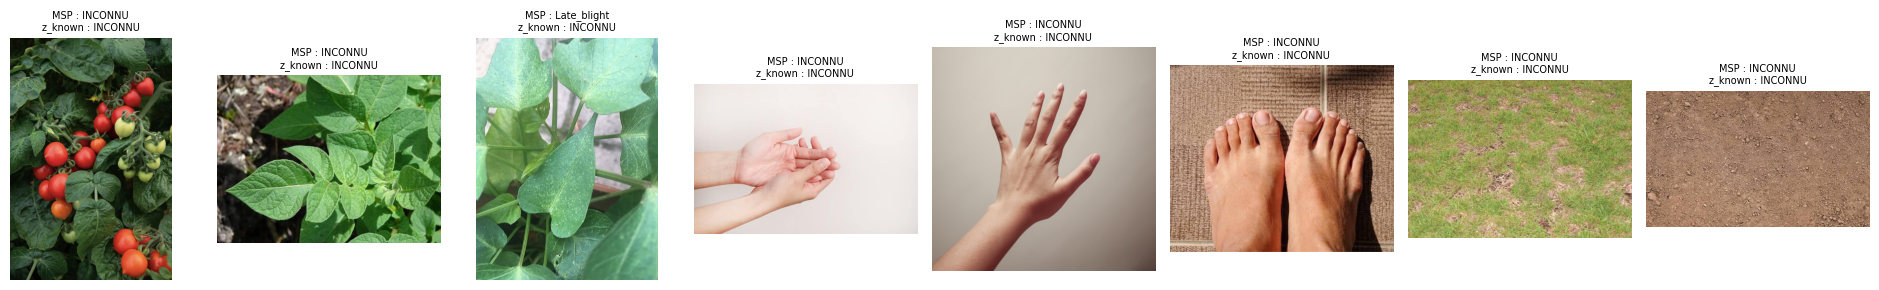

In [14]:
# Exemples de photos personnelles : décision de chaque système
if "photos personnelles" in scores:
    s = scores["photos personnelles"]
    files = ood_sets["photos personnelles"][:8]
    fig, axes = plt.subplots(1, len(files), figsize=(2.4 * len(files), 3))
    dep_name = P4["deploy_system"]
    rej = {n: sys_scores(n, s) > rules[n]["tau"] for n in ("msp", dep_name)}
    for i, f in enumerate(files):
        axes[i].imshow(plt.imread(f))
        verdict = ["INCONNU" if rej[n][i] else KNOWN[s["pred"][i]][:12] for n in ("msp", dep_name)]
        axes[i].set_title(f"MSP : {verdict[0]}\n{dep_name} : {verdict[1]}", fontsize=7)
        axes[i].axis("off")
    fig.tight_layout()
    fig.savefig(OUT / "ood_custom_examples.png", dpi=130)

7. Système de la démonstration

Fixé **a priori** dans le config (`part4.deploy_system`, par défaut `z_known`) et non d'après le tableau ci-dessus : choisir le système d'après le test reviendrait à sélectionner sur le test.

In [15]:
dep = P4["deploy_system"]
decision = {
    "system": dep, "rule": rules[dep], "known_classes": KNOWN, "unknown_class_held_out": M,
    "classifier": {"backbone": P4["backbone"], "ckpt": str((exp_clf / "best.pt").relative_to(paths["results"])),
                   "img_size": S_CLS, "mean": IMAGENET_MEAN, "std": IMAGENET_STD},
    "autoencoder": {"latent_dim": best_ae_info["latent_dim"], "img_size": S_AE,
                    "ckpt": str(((exp_aek if rules[dep]["ae"] == "ae_known" else paths["results"] / best_ae_info["exp_dir"]) / "best.pt").relative_to(paths["results"]))
                    if rules[dep]["ae"] else None},
}
save_json(decision, OUT / "decision_rule.json")
decision["system"], results.loc[dep].to_dict()

('z_known',
 {'auroc_known_vs_unknown': 0.7835,
  'reject_rate_unknown': 0.4906,
  'false_reject_rate_known': 0.0596,
  'accuracy_on_accepted_known': 0.9992,
  'coverage_known': 0.9404})